# Reproducible analysis of biomedical engineering internship competencies
**Manuscript:** *Competency Development During Biomedical Engineering Internships in Costa Rica: Student and Supervisor Perspectives on Workplace Learning*.

This notebook reproduces Tables 1–4 and Figures 1–3 from individual survey responses. It covers quantitative competency ratings only. Personally identifying fields are not displayed or exported.

**How to run:** Place the two original XLSX survey files and the manuscript DOCX in the same folder as this notebook, then select **Run All**. Required packages: `pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`, `python-docx`, and `openpyxl`.

**Figure design:** The visual hierarchy, color families, marker shapes, applicability bars, significance outlines, and plot arrangement follow the manuscript figures. These are programmatic recreations rather than pixel-identical copies.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT=Path.cwd()
STUDENT=next(ROOT.glob('*STUDENTS*.xlsx'))
SUPERVISOR=next(ROOT.glob('*SUPERVISOR*.xlsx'))
OUT=ROOT/'reproduced_results';OUT.mkdir(exist_ok=True)
students=pd.read_excel(STUDENT)
supervisors=pd.read_excel(SUPERVISOR)
assert len(students)==53 and len(supervisors)==17
print('Students:',len(students),'Supervisors:',len(supervisors))

Students: 53 Supervisors: 17


In [2]:
pattern=re.compile(r'^\d+\.\s*(.*?)\s*\[(.*?)\]$')
def column_map(frame):
    return {(m.group(1).strip(),m.group(2).strip()):col for col in frame.columns if (m:=pattern.match(str(col)))}
student_columns=column_map(students)
supervisor_columns=column_map(supervisors)
competencies=list(dict.fromkeys(name for name,_ in student_columns))
assert len(competencies)==23

def rating(frame, mapping, competency, dimension):
    return pd.to_numeric(frame[mapping[competency,dimension]],errors='coerce')
def descriptive(frame,mapping,dimension):
    records=[]
    for competency in competencies:
        x=rating(frame,mapping,competency,dimension).dropna()
        records.append({'Competency':competency,'n':len(x),'mean':x.mean(), 'sd':x.std(ddof=1),'applicability':100*len(x)/len(frame)})
    return pd.DataFrame(records).set_index('Competency')
SP=descriptive(students,student_columns,'Initial Preparation')
SI=descriptive(students,student_columns,'Importance')
SE=descriptive(students,student_columns,'Performance')
VI=descriptive(supervisors,supervisor_columns,'Importance')
VE=descriptive(supervisors,supervisor_columns,'Performance')
print('Average of 23 competency means:', {k:round(x['mean'].mean(),3) for k,x in {'SP':SP,'SI':SI,'SE':SE,'VI':VI,'VE':VE}.items()})

Average of 23 competency means: {'SP': np.float64(3.843), 'SI': np.float64(4.243), 'SE': np.float64(4.213), 'VI': np.float64(4.075), 'VE': np.float64(3.858)}


## Table 1. Participants and internship placements
Frequency counts are derived directly from the survey demographic fields. Original response labels are retained to avoid undocumented recoding.

In [3]:
def freq(frame,column,group):
    counts=frame[column].fillna('Missing').value_counts()
    return pd.DataFrame({'Group':group,'Category':counts.index,'n':counts.values,'%':(counts.values/len(frame)*100).round(1)})
table1=pd.concat([freq(students,students.columns[5],'Students: organization'),freq(students,students.columns[6],'Students: function'),freq(supervisors,supervisors.columns[5],'Supervisors: organization'),freq(supervisors,supervisors.columns[7],'Supervisors: experience')],ignore_index=True)
display(table1);table1.to_csv(OUT/'tabla1_participantes.csv',index=False)

,Group,Category,n,%
0,Students: organization,Medical device manufacturing company,36,67.9
1,Students: organization,Hospital or medical center,6,11.3
2,Students: organization,"Other type of private company (e.g., consultin...",5,9.4
3,Students: organization,Research center or research institute,4,7.5
4,Students: organization,Farmacéutica,1,1.9
5,Students: organization,Pharma company,1,1.9
6,Students: function,Quality assurance / quality control,18,34.0
7,Students: function,Manufacturing / production,11,20.8
8,Students: function,Research and development,8,15.1
9,Students: function,Technical support / field engineering,6,11.3


## Tables 2 and 3. Competency-level descriptive statistics
Sample standard deviations use `ddof=1`. “Not applicable” and blank entries are excluded from means and SDs. Applicability is the percentage of respondents providing a numeric rating.

In [4]:
def fmt(frame):return frame['mean'].map(lambda x:f'{x:.2f}')+' ('+frame['sd'].map(lambda x:f'{x:.2f}')+')'
table2=pd.DataFrame({'Preparation M (SD)':fmt(SP),'Importance M (SD)':fmt(SI),'Performance M (SD)':fmt(SE),'Applicability %':SI['applicability'].round(1)})
table3=pd.DataFrame({'Importance M (SD)':fmt(VI),'Performance M (SD)':fmt(VE),'Valid n':VE['n'],'Applicability %':VE['applicability'].round(1)})
display(table2,table3)
table2.to_csv(OUT/'tabla2_estudiantes.csv');table3.to_csv(OUT/'tabla3_supervisores.csv')

,Preparation M (SD),Importance M (SD),Performance M (SD),Applicability %
Competency,,,,
Fabrication technologies,3.57 (1.17),4.14 (1.09),4.00 (1.11),79.2
Statistics,3.60 (1.12),4.35 (0.84),4.17 (0.86),90.6
Team projects,4.55 (0.70),4.57 (0.75),4.68 (0.58),100.0
Manufacturing,3.77 (1.04),4.43 (0.89),4.39 (0.80),86.8
Programming,3.31 (1.33),3.56 (1.14),3.60 (1.16),84.9
Writing,4.34 (0.90),4.74 (0.62),4.58 (0.69),100.0
Verification and validation,3.69 (1.36),4.61 (0.72),4.53 (0.76),96.2
Biomechanics,3.66 (1.35),3.82 (1.35),3.93 (1.28),84.9
Problem solving,4.32 (0.89),4.70 (0.57),4.58 (0.63),100.0


,Importance M (SD),Performance M (SD),Valid n,Applicability %
Competency,,,,
Fabrication technologies,3.92 (1.44),3.82 (1.40),11,64.7
Statistics,4.13 (1.19),3.93 (1.10),15,88.2
Team projects,4.94 (0.24),4.59 (0.80),17,100.0
Manufacturing,4.00 (1.32),3.82 (1.51),17,100.0
Programming,3.33 (1.37),3.25 (1.22),12,70.6
Writing,4.94 (0.24),4.53 (0.87),17,100.0
Verification and validation,4.73 (0.46),4.40 (0.74),15,88.2
Biomechanics,3.42 (1.56),3.73 (1.49),11,64.7
Problem solving,4.69 (0.48),4.06 (1.18),16,94.1


## Within-group statistical comparisons
Two-sided paired Wilcoxon signed-rank tests use complete pairs, with Benjamini–Hochberg adjustment within each family of 23 comparisons. Preparation–performance contrasts should not be interpreted as causal learning gains.

In [5]:
def paired_tests(frame,mapping,left,right):
    results=[]
    for name in competencies:
        x=rating(frame,mapping,name,left);y=rating(frame,mapping,name,right)
        valid=x.notna()&y.notna();diff=x[valid]-y[valid]
        p=wilcoxon(diff).pvalue if (diff!=0).any() else 1.0
        results.append({'Competency':name,'paired_n':valid.sum(),'mean_right_minus_left':-diff.mean(),'p':p})
    out=pd.DataFrame(results).set_index('Competency')
    out['q_BH']=multipletests(out['p'],method='fdr_bh')[1]
    out['significant']=out['q_BH']<.05
    return out
SP_SE=paired_tests(students,student_columns,'Initial Preparation','Performance')
SI_SE=paired_tests(students,student_columns,'Importance','Performance')
VI_VE=paired_tests(supervisors,supervisor_columns,'Importance','Performance')
for label,result in [('student_prep_perf',SP_SE),('student_imp_perf',SI_SE),('supervisor_imp_perf',VI_VE)]:
    print(label,'significant comparisons:',result.significant.sum());result.to_csv(OUT/(label+'.csv'))

student_prep_perf significant comparisons: 16
student_imp_perf significant comparisons: 0
supervisor_imp_perf significant comparisons: 0


## Table 4. Independent student–supervisor comparisons
Two-sided Mann–Whitney U tests; Cliff’s delta is defined as `P(supervisor > student) − P(supervisor < student)`. BH adjustment is applied separately to the importance and performance families.

In [6]:
def between(dimension):
    records=[]
    for name in competencies:
        a=rating(students,student_columns,name,dimension).dropna().to_numpy()
        b=rating(supervisors,supervisor_columns,name,dimension).dropna().to_numpy()
        p=mannwhitneyu(b,a,alternative='two-sided').pvalue
        delta=(np.sum(b[:,None]>a[None,:])-np.sum(b[:,None]<a[None,:]))/(len(a)*len(b))
        records.append({'Competency':name,'Student n':len(a),'Supervisor n':len(b),'Δ mean':b.mean()-a.mean(),'Cliff δ':delta,'p':p})
    result=pd.DataFrame(records).set_index('Competency')
    result['Adjusted p']=multipletests(result.p,method='fdr_bh')[1]
    return result
comparison_I=between('Importance');comparison_E=between('Performance')
display(comparison_I.round(3),comparison_E.round(3))
comparison_I.to_csv(OUT/'tabla4A_importancia.csv');comparison_E.to_csv(OUT/'tabla4B_desempeno.csv')

,Student n,Supervisor n,Δ mean,Cliff δ,p,Adjusted p
Competency,,,,,,
Fabrication technologies,42,12,-0.226,-0.060,0.744,0.883
Statistics,48,15,-0.221,-0.078,0.624,0.883
Team projects,53,17,0.375,0.266,0.032,0.367
Manufacturing,46,17,-0.435,-0.187,0.201,0.883
Programming,45,12,-0.222,-0.106,0.571,0.883
Writing,53,17,0.205,0.133,0.197,0.883
Verification and validation,51,15,0.125,0.034,0.806,0.883
Biomechanics,45,12,-0.406,-0.161,0.378,0.883
Problem solving,53,16,-0.011,-0.050,0.703,0.883


,Student n,Supervisor n,Δ mean,Cliff δ,p,Adjusted p
Competency,,,,,,
Fabrication technologies,40,11,-0.182,-0.036,0.856,0.996
Statistics,48,15,-0.233,-0.101,0.536,0.823
Team projects,53,17,-0.091,-0.022,0.869,0.996
Manufacturing,46,17,-0.568,-0.169,0.260,0.564
Programming,45,12,-0.350,-0.169,0.363,0.696
Writing,53,17,-0.055,0.009,0.953,0.996
Verification and validation,51,15,-0.129,-0.120,0.414,0.698
Biomechanics,43,11,-0.203,-0.072,0.707,0.957
Problem solving,53,16,-0.522,-0.233,0.104,0.477


## Figure 1. Student-rated competencies during internships

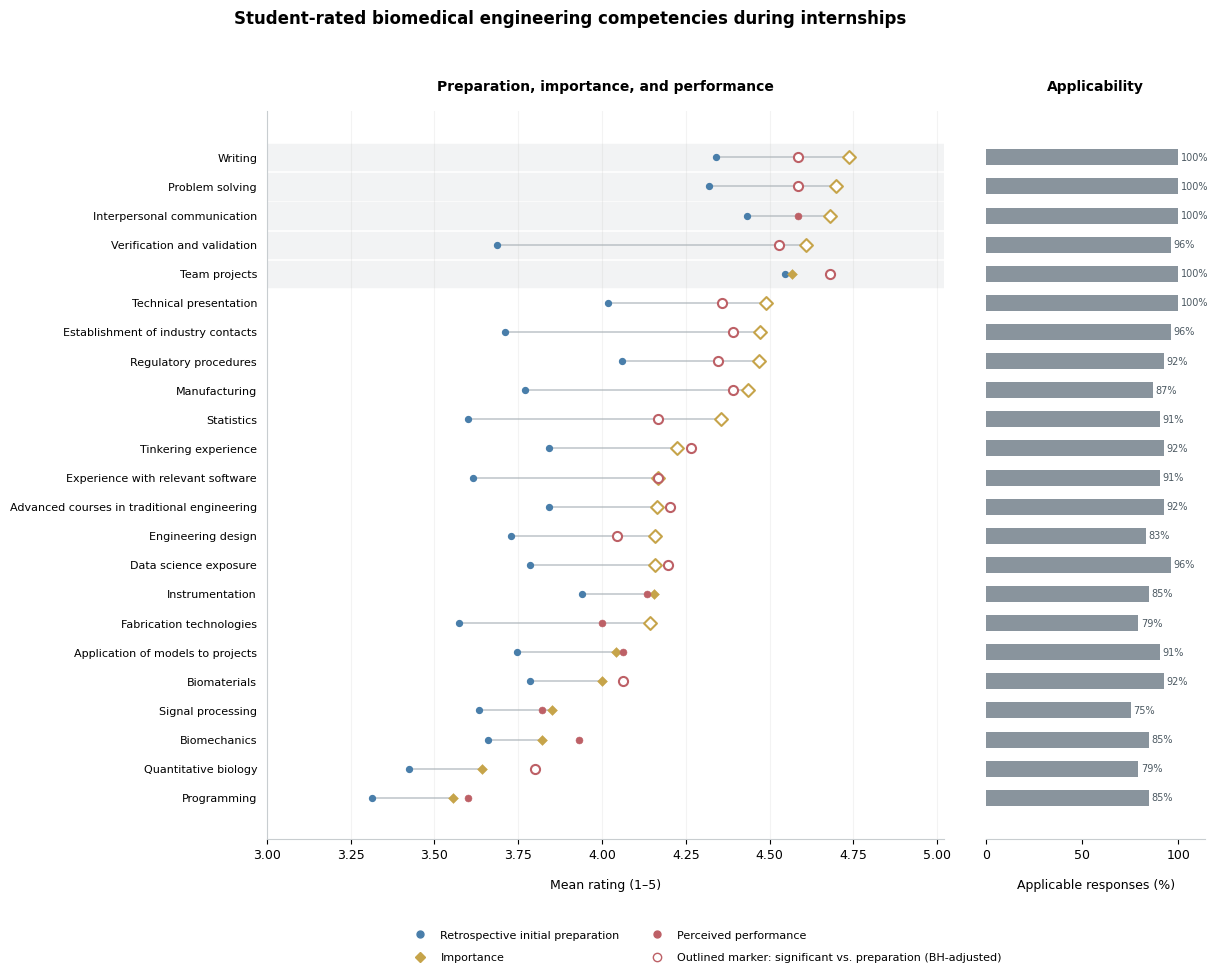

In [7]:
# Manuscript-inspired publication style
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
GOLD='#C6A44A'; RED='#BD6066'; BLUE='#497EAA'; PURPLE='#7C5AA6'; BAR='#89949D'; PALE='#E9EDF0'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.titlesize':11,'axes.labelsize':9,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','axes.spines.top':False,'axes.spines.right':False})
def competency_profile(importance,performance,preparation=None,paired_importance=None,paired_performance=None,title='',filename='figure.png'):
    # The paper ranks competencies by importance, descending from top to bottom.
    ordered=importance['mean'].sort_values(ascending=False).index
    y=np.arange(len(ordered))
    fig=plt.figure(figsize=(13.5,10.7))
    gs=fig.add_gridspec(1,2,width_ratios=[3.25,1.05],left=.275,right=.97,top=.87,bottom=.19,wspace=.095)
    ax=fig.add_subplot(gs[0,0]);bx=fig.add_subplot(gs[0,1],sharey=ax)
    fig.suptitle(title,fontsize=12,fontweight='bold',y=.965)
    ax.set_title('Preparation, importance, and performance' if preparation is not None else 'Importance and performance',fontsize=10,fontweight='bold',pad=15)
    bx.set_title('Applicability',fontsize=10,fontweight='bold',pad=15)
    if preparation is not None:
        ax.scatter(preparation.loc[ordered,'mean'],y,s=18,color=BLUE,marker='o',zorder=4,label='Retrospective initial preparation')
    for k,name in enumerate(ordered):
        if k<5:ax.axhspan(k-.45,k+.45,color='#F2F3F4',zorder=0)
        start=(preparation if preparation is not None else performance).loc[name,'mean']
        stop=importance.loc[name,'mean']
        ax.plot([start,stop],[k,k],color='#A8B0B6',lw=1.1,alpha=.75,zorder=1)
    def scatter(values,color,marker,significance,label):
        for k,name in enumerate(ordered):
            sig=significance is not None and bool(significance.loc[name,'significant'])
            ax.scatter([values.loc[name,'mean']],[k],marker=marker,s=43 if sig else 25,
                       facecolor='white' if sig else color,edgecolor=color,linewidth=1.5 if sig else .4,zorder=5)
    scatter(importance,GOLD,'D',paired_importance,'Importance')
    scatter(performance,RED,'o',paired_performance,'Perceived performance')
    ax.set_yticks(y,ordered);ax.tick_params(axis='y',length=0,pad=7,labelsize=8)
    ax.invert_yaxis();ax.set_xlim(2.7 if preparation is None else 3,5.02)
    ax.set_xlabel('Mean rating (1–5)',labelpad=12);ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    for spine in ['left','bottom']:ax.spines[spine].set_color('#C8CDD0')
    applicable=importance.loc[ordered,'applicability'].to_numpy()
    bx.barh(y,applicable,color=BAR,height=.55)
    bx.set_xlim(0,114);bx.set_xticks([0,50,100]);bx.set_xlabel('Applicable responses (%)',labelpad=12)
    bx.tick_params(axis='y',left=False,labelleft=False)
    bx.spines['left'].set_visible(False);bx.spines['bottom'].set_color('#C8CDD0')
    for k,v in enumerate(applicable):bx.text(v+1.3,k,f'{v:.0f}%',va='center',fontsize=7,color='#4C5962')
    legend=[]
    if preparation is not None:legend.append(Line2D([0],[0],marker='o',linestyle='None',color=BLUE,markersize=5,label='Retrospective initial preparation'))
    legend += [Line2D([0],[0],marker='D',linestyle='None',color=GOLD,markersize=5,label='Importance'),Line2D([0],[0],marker='o',linestyle='None',color=RED,markersize=5,label='Perceived performance')]
    if preparation is not None:legend.append(Line2D([0],[0],marker='o',linestyle='None',markerfacecolor='white',markeredgecolor=RED,markersize=6,label='Outlined marker: significant vs. preparation (BH-adjusted)'))
    fig.legend(handles=legend,loc='lower center',bbox_to_anchor=(.60,.065),ncol=2,frameon=False,fontsize=8,columnspacing=2.4,labelspacing=1.1)
    fig.savefig(OUT/filename,dpi=260,bbox_inches='tight');plt.show()

competency_profile(SI,SE,preparation=SP,paired_importance=paired_tests(students,student_columns,'Initial Preparation','Importance'),paired_performance=SP_SE,title='Student-rated biomedical engineering competencies during internships',filename='figure1_students.png')

## Figure 2. Supervisor-rated competencies during internships

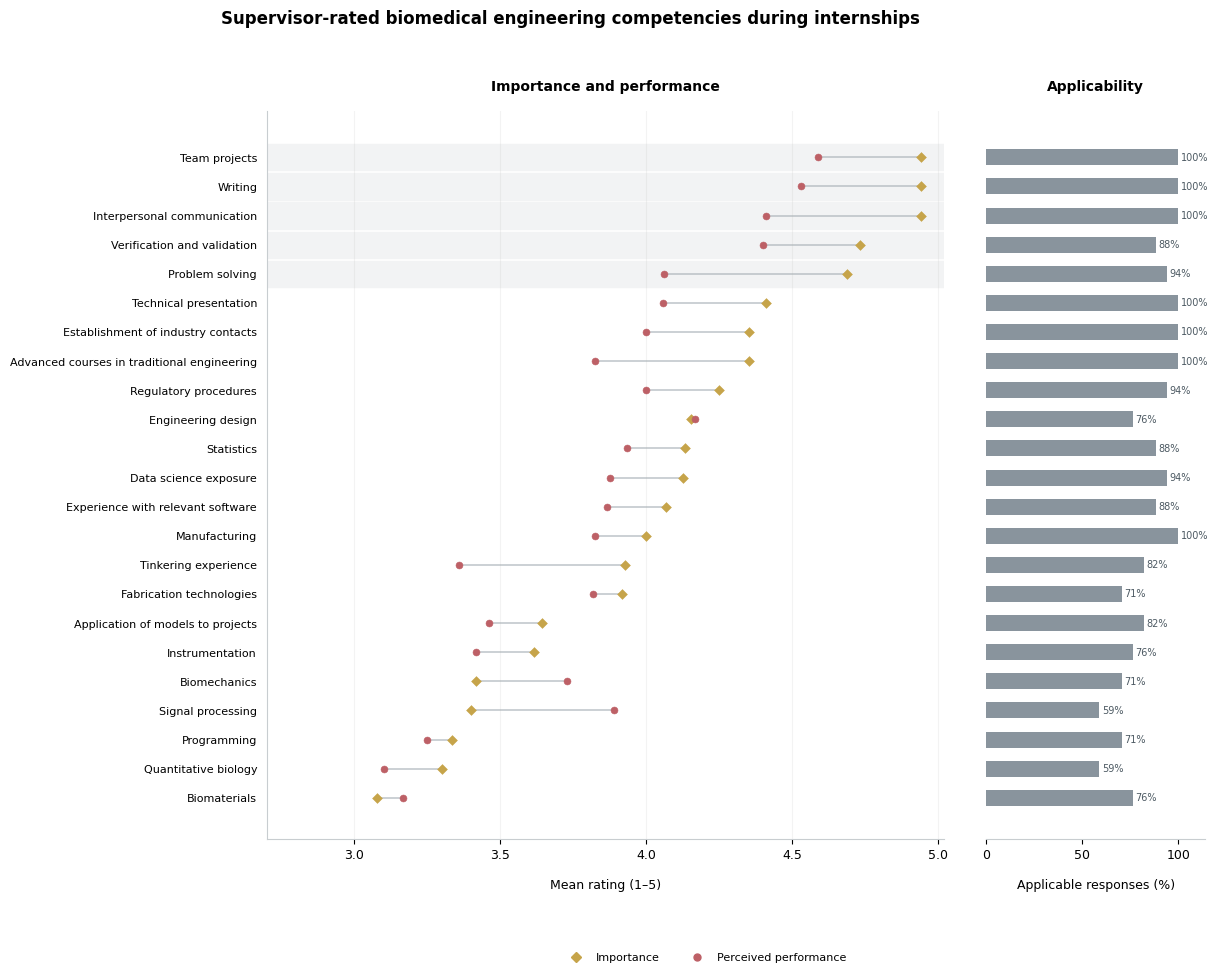

In [8]:
competency_profile(VI,VE,title='Supervisor-rated biomedical engineering competencies during internships',filename='figure2_supervisors.png')

## Figure 3. Correspondence between independent student and supervisor profiles

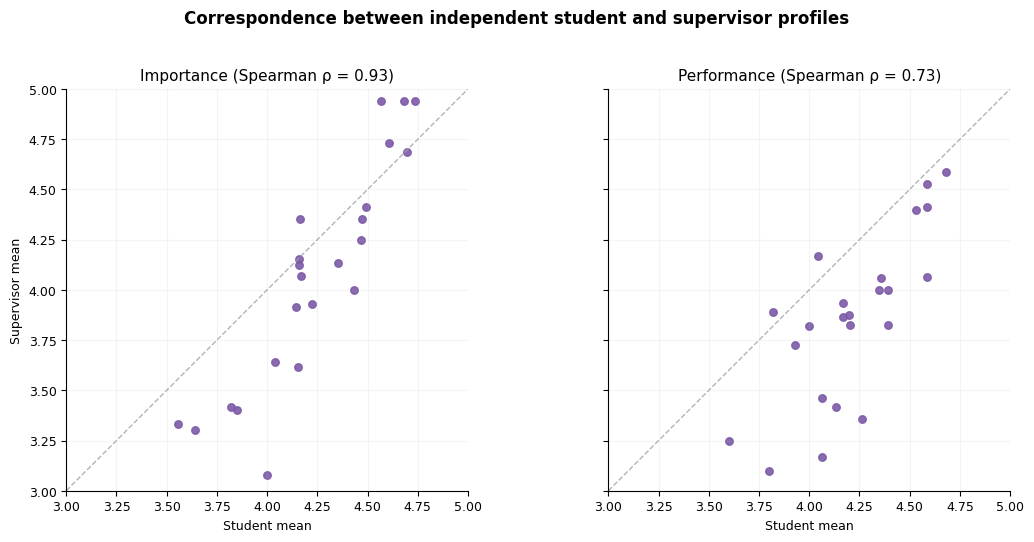

In [9]:
fig,axes=plt.subplots(1,2,figsize=(11.4,5.4),sharex=True,sharey=True)
for ax,x,y,label in [(axes[0],SI,VI,'Importance'),(axes[1],SE,VE,'Performance')]:
    rho,p=spearmanr(x['mean'],y['mean'])
    ax.scatter(x['mean'],y['mean'],s=29,color=PURPLE,alpha=.90)
    ax.plot([3,5],[3,5],ls='--',lw=1,color='#9BA2A9',alpha=.8)
    ax.set(xlim=(3,5),ylim=(3,5),xlabel='Student mean',title=f'{label} (Spearman ρ = {rho:.2f})')
    ax.grid(alpha=.13)
    ax.set_aspect('equal',adjustable='box')
axes[0].set_ylabel('Supervisor mean')
fig.suptitle('Correspondence between independent student and supervisor profiles',fontweight='bold',fontsize=12,y=.98)
fig.tight_layout(rect=[0,0,1,.94]);fig.savefig(OUT/'figure3_profile_correspondence.png',dpi=260,bbox_inches='tight');plt.show()